In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Del 2: Väder

## Vad vill vi ta reda på?
I del 1 såg vi att timme och ledig dag säger en hel del om uthyrningen, men att en gissning
med bara tiden fortfarande blir ungefär 400 cyklar fel per timme.

I den här delen tittar vi på vädret. Vilka väderfaktorer hänger ihop med uthyrningen,
och spelar vädret lika stor roll hela dygnet?

In [2]:
df = pd.read_csv("../data/SeoulBikeData.csv", encoding="cp1252")
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

# Samma rensning som i del 1
df = df[df["Functioning Day"] == "Yes"].copy()

# Ledig dag från del 1 (helg eller helgdag)
df["Ledig dag"] = (df["Date"].dt.day_of_week >= 5) | (df["Holiday"] == "Holiday")

TARGET = "Rented Bike Count"
VADER = [
	"Temperature(°C)",
	"Humidity(%)",
	"Wind speed (m/s)",
	"Visibility (10m)",
	"Dew point temperature(°C)",
	"Solar Radiation (MJ/m2)",
	"Rainfall(mm)",
	"Snowfall (cm)",
]

print("Timmar:", len(df))
print("Väderkolumner:", len(VADER))

Timmar: 8465
Väderkolumner: 8


## Vilka väderfaktorer hänger ihop med uthyrningen?
Vi börjar med korrelationen mellan varje väderkolumn och antal uthyrda cyklar.

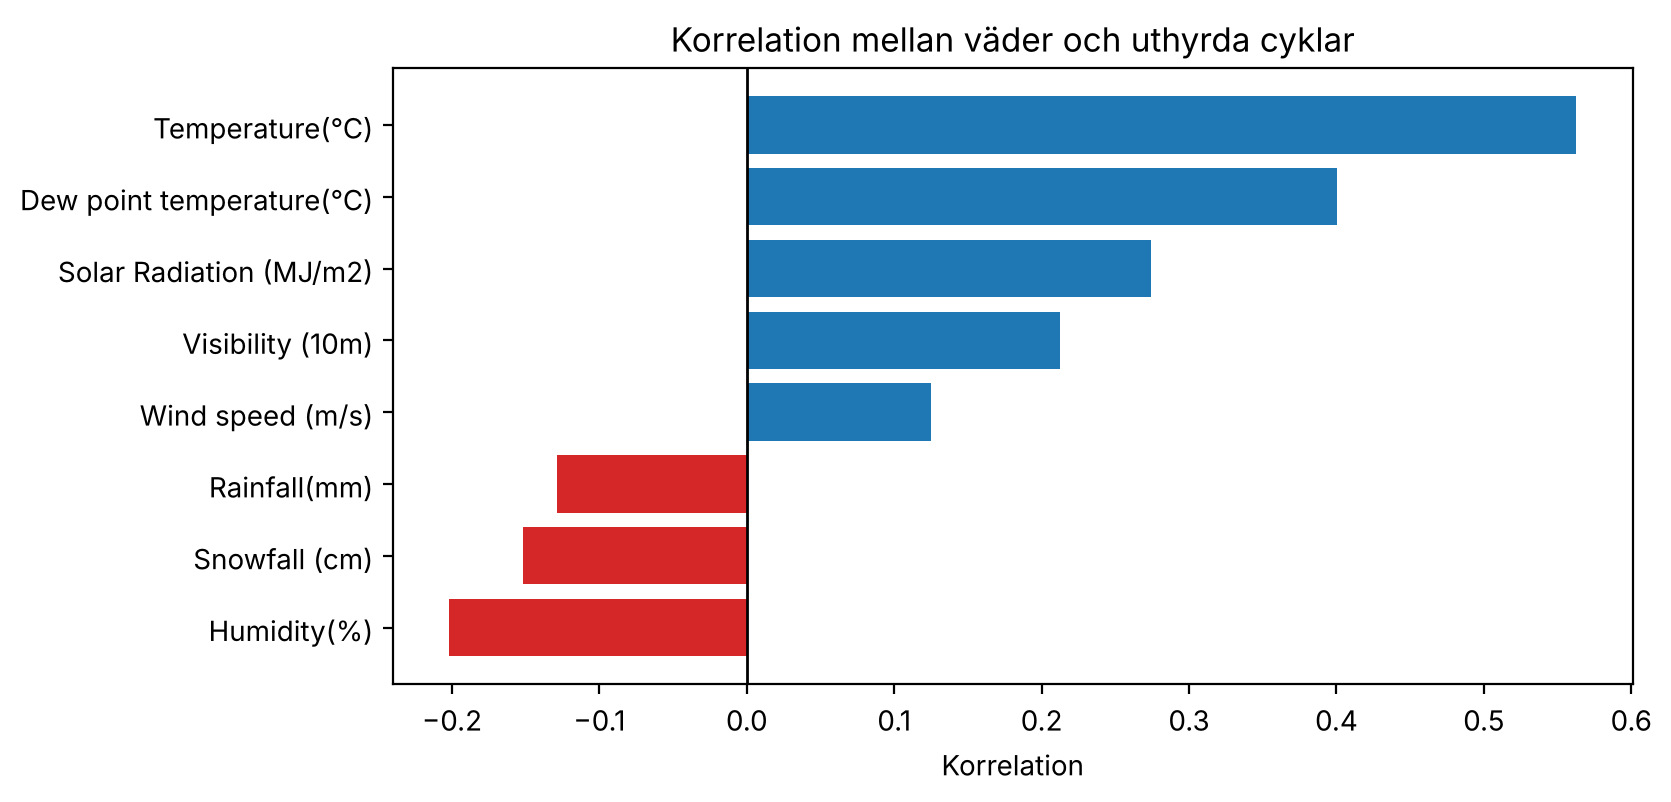

Humidity(%)                 -0.20
Snowfall (cm)               -0.15
Rainfall(mm)                -0.13
Wind speed (m/s)             0.13
Visibility (10m)             0.21
Solar Radiation (MJ/m2)      0.27
Dew point temperature(°C)    0.40
Temperature(°C)              0.56
dtype: float64

In [3]:
korr = df[VADER].corrwith(df[TARGET]).sort_values()

# Blått = fler cyklar när värdet är högt
# Rött = färre
farger = ["tab:blue" if v > 0 else "tab:red" for v in korr]

plt.figure(figsize=(8, 4))
plt.barh(korr.index, korr.values, color=farger)
plt.axvline(0, color="black", linewidth=1)
plt.title("Korrelation mellan väder och uthyrda cyklar")
plt.xlabel("Korrelation")
plt.show()

korr.round(2)

Temperaturen har starkast samband (0,56). Regn och snö ser svaga ut, men korrelationen
visar bara raka samband. Därför tittar vi närmare på varje faktor.

## Temperatur

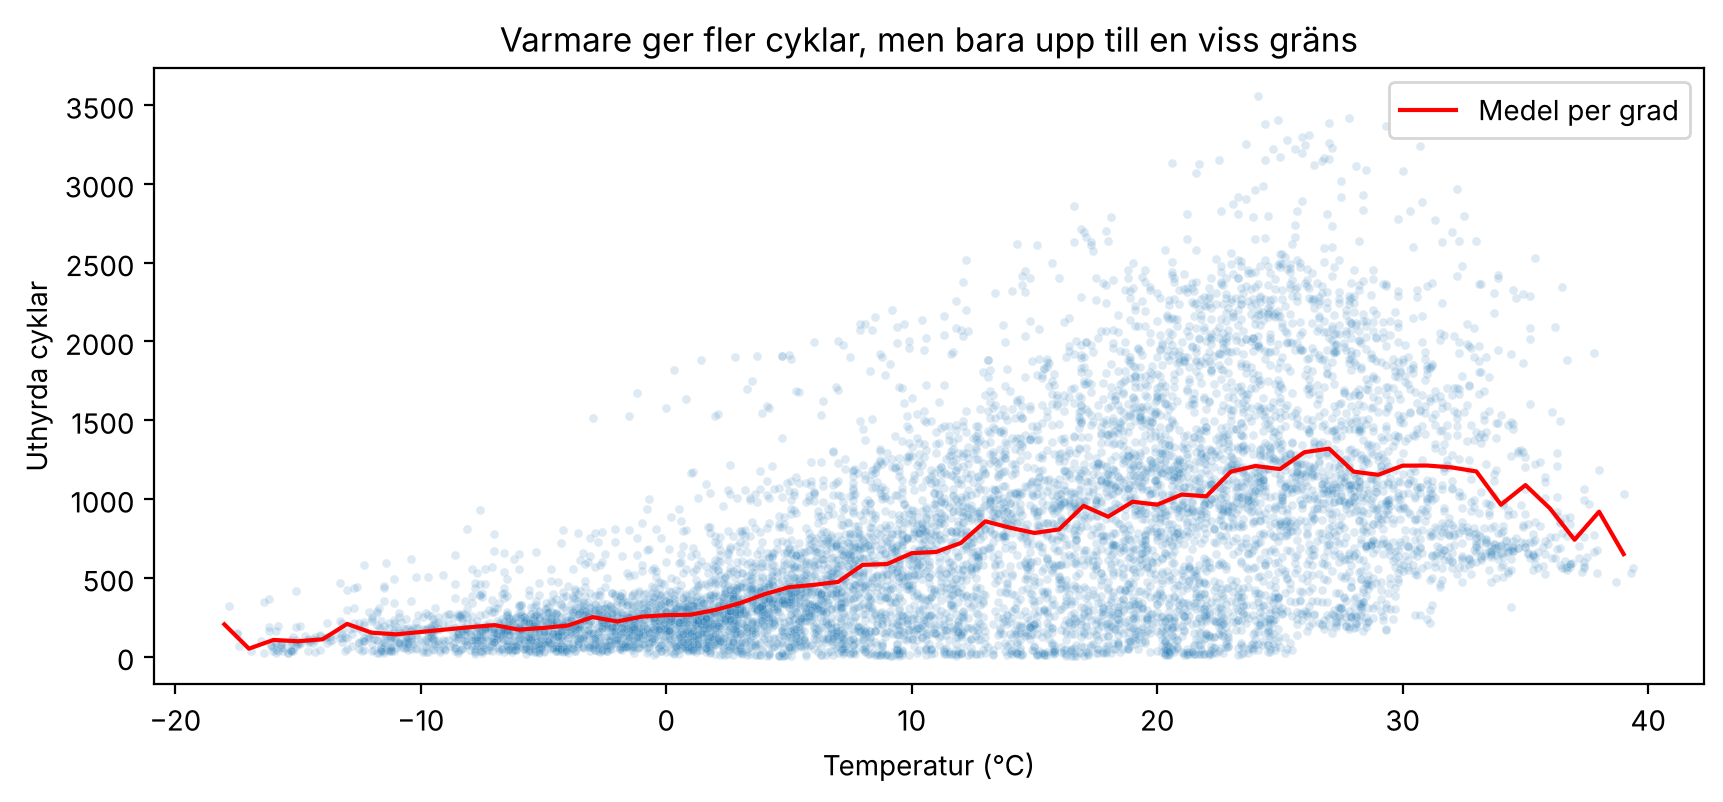

Flest cyklar i snitt vid 27 °C


In [4]:
# Medel per grad så att trenden syns
per_grad = df.groupby(df["Temperature(°C)"].round())[TARGET].mean()

plt.figure(figsize=(10, 4))
sns.scatterplot(data=df, x="Temperature(°C)", y=TARGET, alpha=0.15, s=10)
plt.plot(per_grad.index, per_grad.values, color="red", label="Medel per grad")
plt.title("Varmare ger fler cyklar, men bara upp till en viss gräns")
plt.xlabel("Temperatur (°C)")
plt.ylabel("Uthyrda cyklar")
plt.legend()
plt.show()

print("Flest cyklar i snitt vid", int(per_grad.idxmax()), "°C")

Sambandet är en kurva och ingen rak linje. Uthyrningen ökar från ca 100 cyklar i minusgrader
till ca 1 200 vid 25–30 °C. När det blir varmare än så sjunker den igen.

## Regn

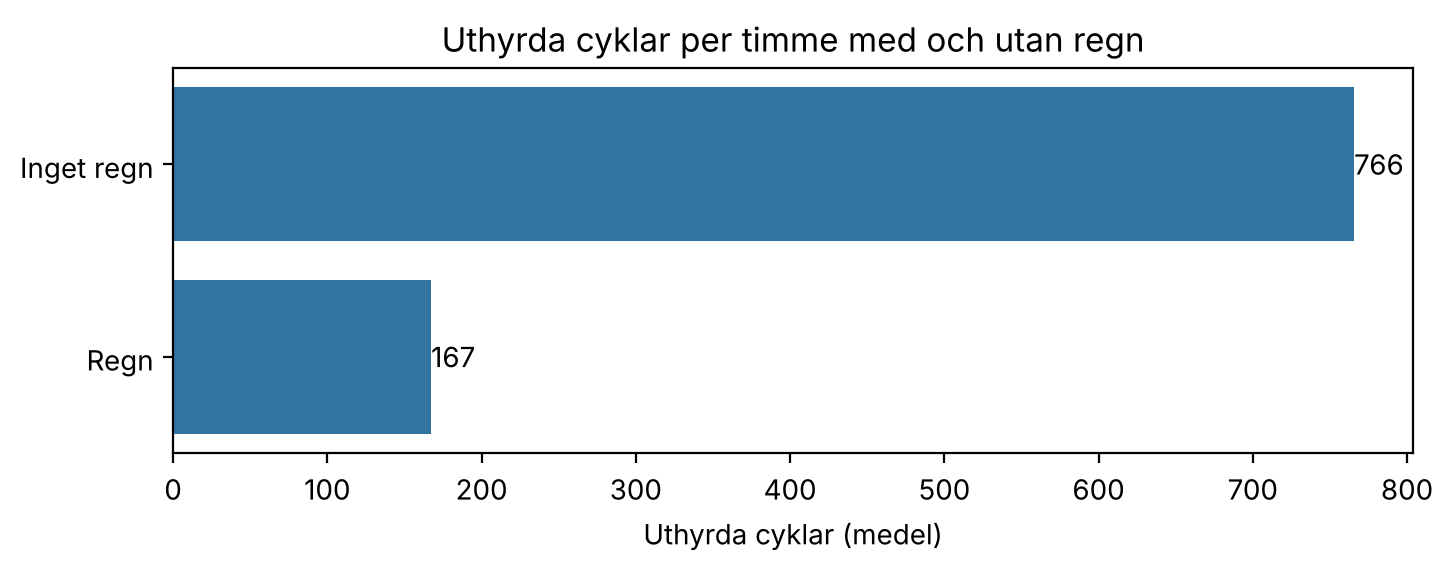

Andel timmar med regn: 6 %


In [5]:
df["Regn"] = df["Rainfall(mm)"] > 0

regn = df.groupby("Regn")[TARGET].mean()
regn.index = ["Inget regn", "Regn"]

plt.figure(figsize=(8, 2.5))
ax = sns.barplot(x=regn.values, y=regn.index, color="tab:blue")
ax.bar_label(ax.containers[0], fmt="%.0f")
plt.title("Uthyrda cyklar per timme med och utan regn")
plt.xlabel("Uthyrda cyklar (medel)")
plt.ylabel("")
plt.show()

print("Andel timmar med regn:", round(df["Regn"].mean() * 100), "%")

När det regnar sjunker uthyrningen från ca 770 till ca 170 cyklar per timme. Korrelationen
blev ändå låg, eftersom det bara regnar 6 % av timmarna. Regn fungerar mer som av eller på.

## Snö
Det snöar bara när det är kallt, och då är uthyrningen redan låg. Vi jämför därför också
bara kalla timmar (under 2 °C) med och utan snö.

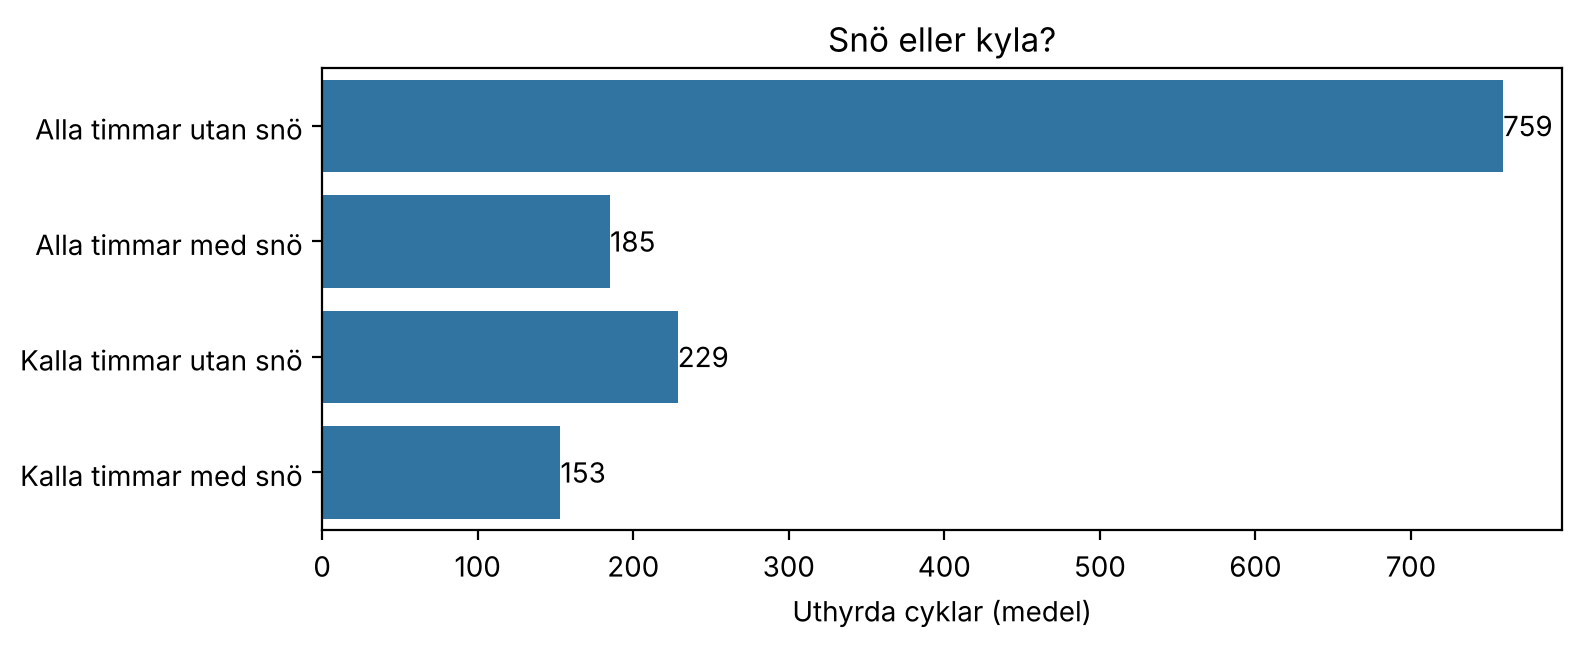

In [ ]:
df["Snö"] = df["Snowfall (cm)"] > 0
kalla = df[df["Temperature(°C)"] < 2]

sno = pd.Series({
	"Alla timmar utan snö": df[~df["Snö"]][TARGET].mean(),
	"Kalla timmar utan snö": kalla[~kalla["Snö"]][TARGET].mean(),
	"Kalla timmar med snö": kalla[kalla["Snö"]][TARGET].mean(),
})

plt.figure(figsize=(8, 3))
ax = sns.barplot(x=sno.values, y=sno.index, color="tab:blue")
ax.bar_label(ax.containers[0], fmt="%.0f")
plt.title("Snö eller kyla?")
plt.xlabel("Uthyrda cyklar (medel)")
plt.ylabel("")
plt.show()

Snö ser ut att sänka uthyrningen lika mycket som regn. Men jämför vi bara kalla timmar är
skillnaden liten, ca 230 mot ca 150. Det mesta av snöns effekt är alltså kylan.

## Luftfuktighet och sol
Solen lyser bara på dagen, så för solen tittar vi bara på timmarna 10–16.

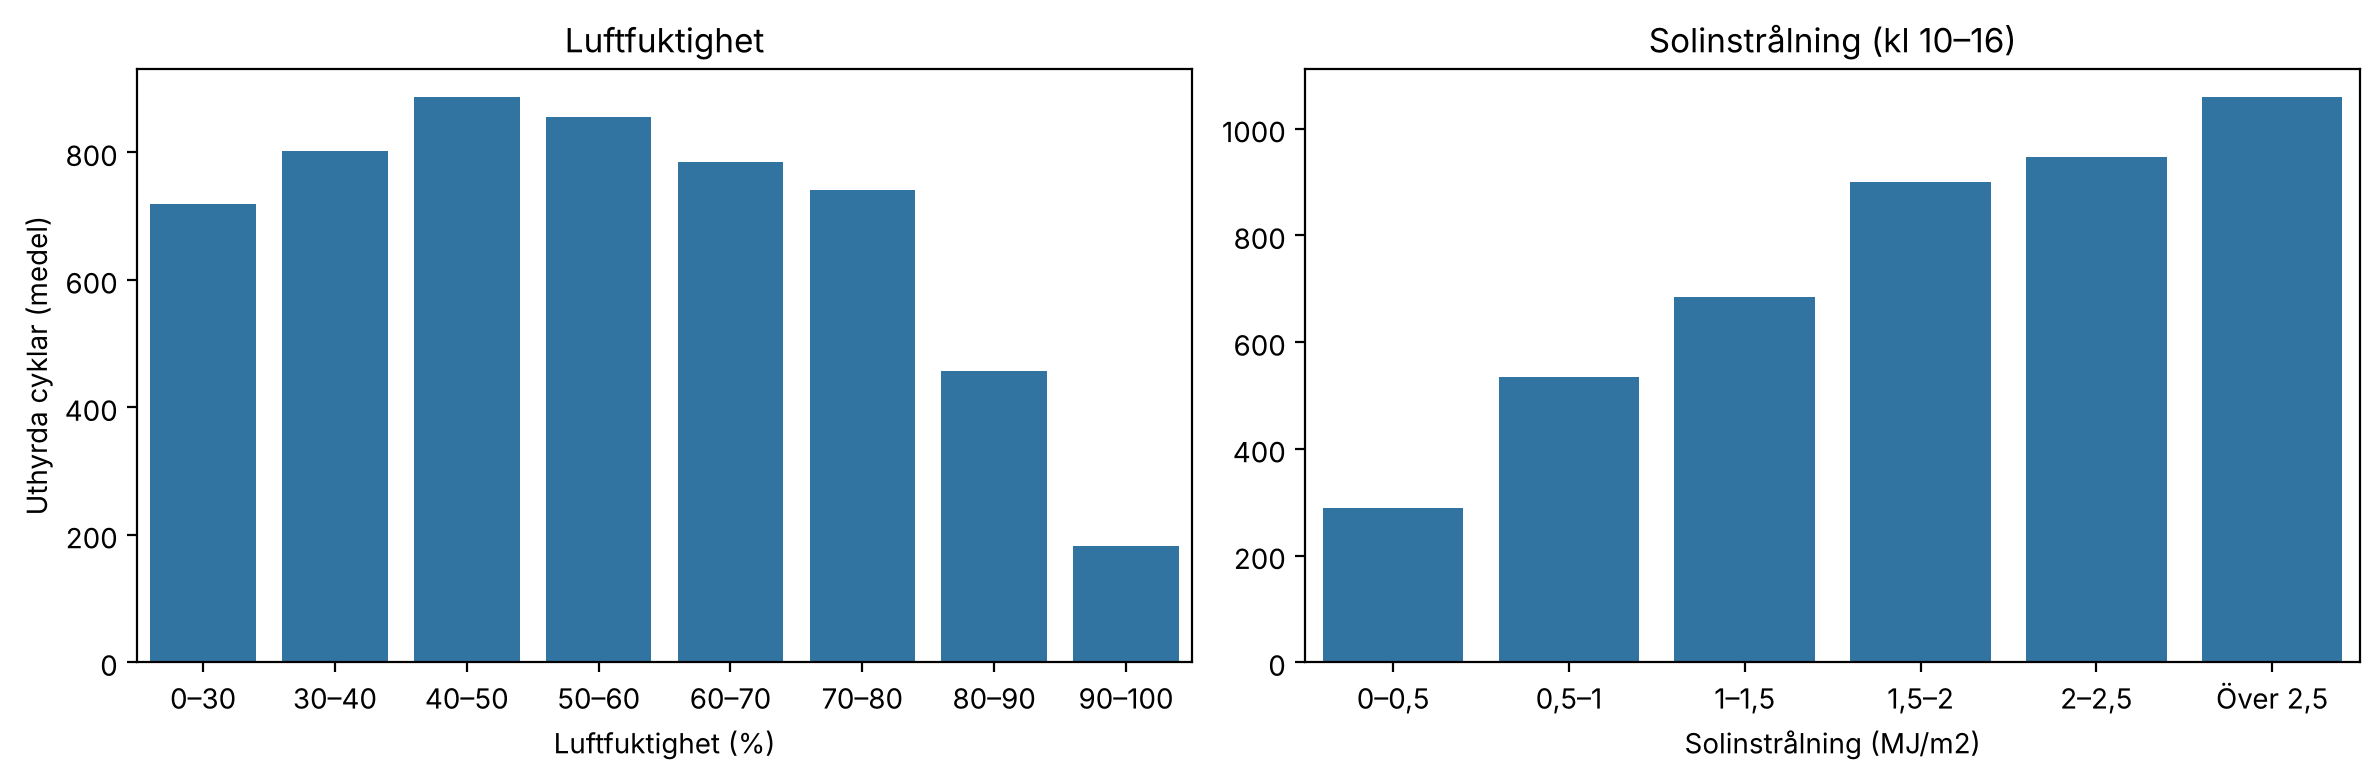

15–25 °C och mulet: 558
15–25 °C och soligt: 1183


In [ ]:
df["Fukt"] = pd.cut(
	df["Humidity(%)"], [0, 30, 40, 50, 60, 70, 80, 90, 100], include_lowest=True,
	labels=["0–30", "30–40", "40–50", "50–60", "60–70", "70–80", "80–90", "90–100"],
)

dagtid = df[df["Hour"].between(10, 16)].copy()
dagtid["Sol"] = pd.cut(
	dagtid["Solar Radiation (MJ/m2)"], [0, 0.5, 1, 1.5, 2, 2.5, 4], include_lowest=True,
	labels=["0–0,5", "0,5–1", "1–1,5", "1,5–2", "2–2,5", "Över 2,5"],
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df, x="Fukt", y=TARGET, errorbar=None, color="tab:blue", ax=ax[0])
ax[0].set_title("Luftfuktighet")
ax[0].set_xlabel("Luftfuktighet (%)")
ax[0].set_ylabel("Uthyrda cyklar (medel)")

sns.barplot(data=dagtid, x="Sol", y=TARGET, errorbar=None, color="tab:blue", ax=ax[1])
ax[1].set_title("Solinstrålning (kl 10–16)")
ax[1].set_xlabel("Solinstrålning (MJ/m2)")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Sol vid samma temperatur (15–25 °C, kl 10–16)
ljumma = dagtid[dagtid["Temperature(°C)"].between(15, 25)]
print("15–25 °C och mulet:", round(ljumma[ljumma["Solar Radiation (MJ/m2)"] <= 1][TARGET].mean()))
print("15–25 °C och soligt:", round(ljumma[ljumma["Solar Radiation (MJ/m2)"] > 1][TARGET].mean()))

**Luftfuktighet:** upp till ca 80 % händer inte så mycket. Över 80 % sjunker uthyrningen
snabbt, och över 90 % är den nere på ca 180. Hög luftfuktighet betyder ofta regn eller dimma.

**Sol:** mer sol ger fler cyklar. En del av det beror på att soliga dagar ofta är varma, men
även vid samma temperatur är det ungefär dubbelt så många cyklar när det är soligt.

## Daggpunkt: säger den något nytt?
Daggpunkten räknas ut från temperatur och luftfuktighet.

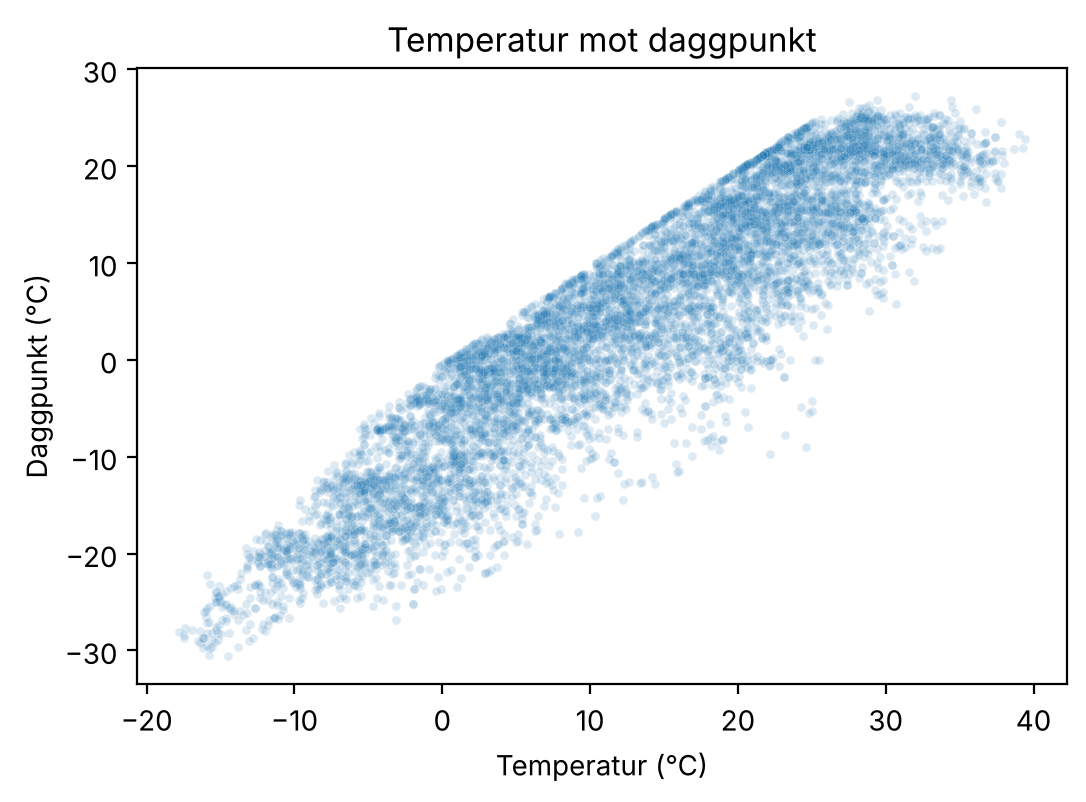

Korrelation: 0.91


In [ ]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="Temperature(°C)", y="Dew point temperature(°C)", alpha=0.15, s=10)
plt.title("Temperatur mot daggpunkt")
plt.xlabel("Temperatur (°C)")
plt.ylabel("Daggpunkt (°C)")
plt.show()

print("Korrelation:", round(df["Temperature(°C)"].corr(df["Dew point temperature(°C)"]), 2))

Daggpunkten följer temperaturen nästan helt (0,91). Den säger alltså samma sak en gång till,
så vi tar inte med den i modellerna.

## Spelar vädret lika stor roll hela dygnet?
I del 1 såg vi att en ledig dag påverkar olika timmar olika mycket. Vi gör samma koll för
temperaturen.

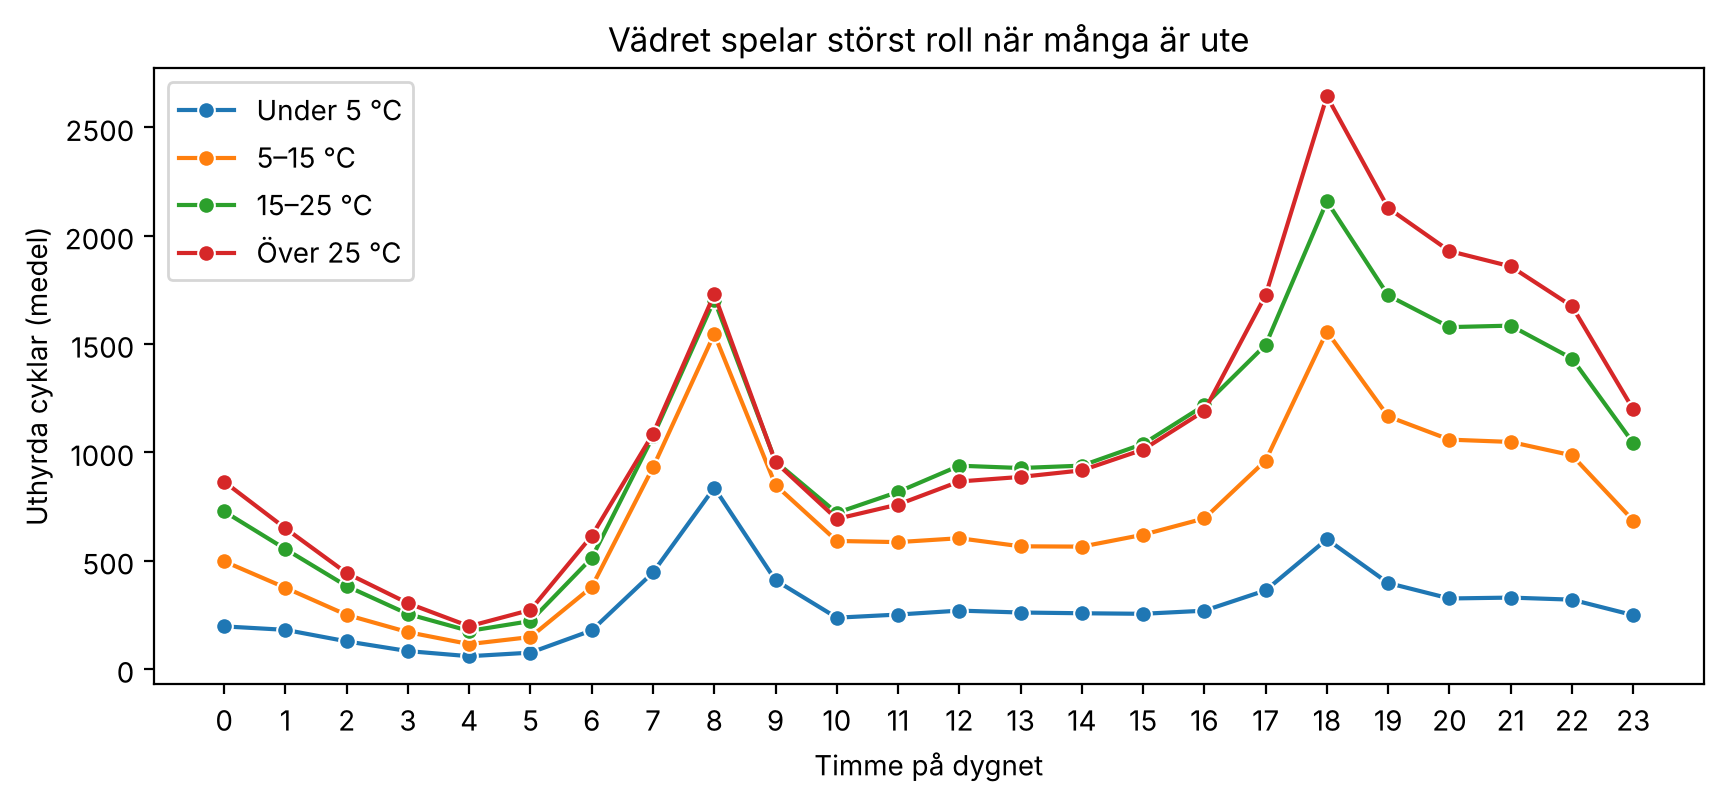

Temperaturgrupp,Under 5 °C,5–15 °C,15–25 °C,Över 25 °C
Hour,,,,
3,83.0,170.0,254.0,304.0
18,599.0,1558.0,2159.0,2644.0


In [ ]:
df["Temperaturgrupp"] = pd.cut(
	df["Temperature(°C)"], [-20, 5, 15, 25, 40],
	labels=["Under 5 °C", "5–15 °C", "15–25 °C", "Över 25 °C"],
)

# Bara vardagar, helgerna har ett annat mönster
vardagar = df[~df["Ledig dag"]]

plt.figure(figsize=(10, 4))
sns.lineplot(data=vardagar, x="Hour", y=TARGET, hue="Temperaturgrupp", errorbar=None, marker="o")
plt.title("Vädret spelar störst roll när många är ute")
plt.xlabel("Timme på dygnet")
plt.ylabel("Uthyrda cyklar (medel)")
plt.xticks(range(24))
plt.legend(title="")
plt.show()

vardagar[vardagar["Hour"].isin([3, 18])].pivot_table(
	index="Hour", columns="Temperaturgrupp", values=TARGET, aggfunc="mean", observed=True
).round()

Kl 18 hyrs ca 600 cyklar när det är under 5 °C och ca 2 600 när det är över 25 °C.
Kl 03 är skillnaden bara ca 200 cyklar.

**Vädret och timmen hänger ihop.** Varmt väder ger många fler cyklar i rusningstid, men
nästan inga fler mitt i natten.

## Referenspunkt: hur mycket hjälper vädret utan maskininlärning?
Vi gör samma tabellgissning som i del 1 och lägger till temperaturgruppen.

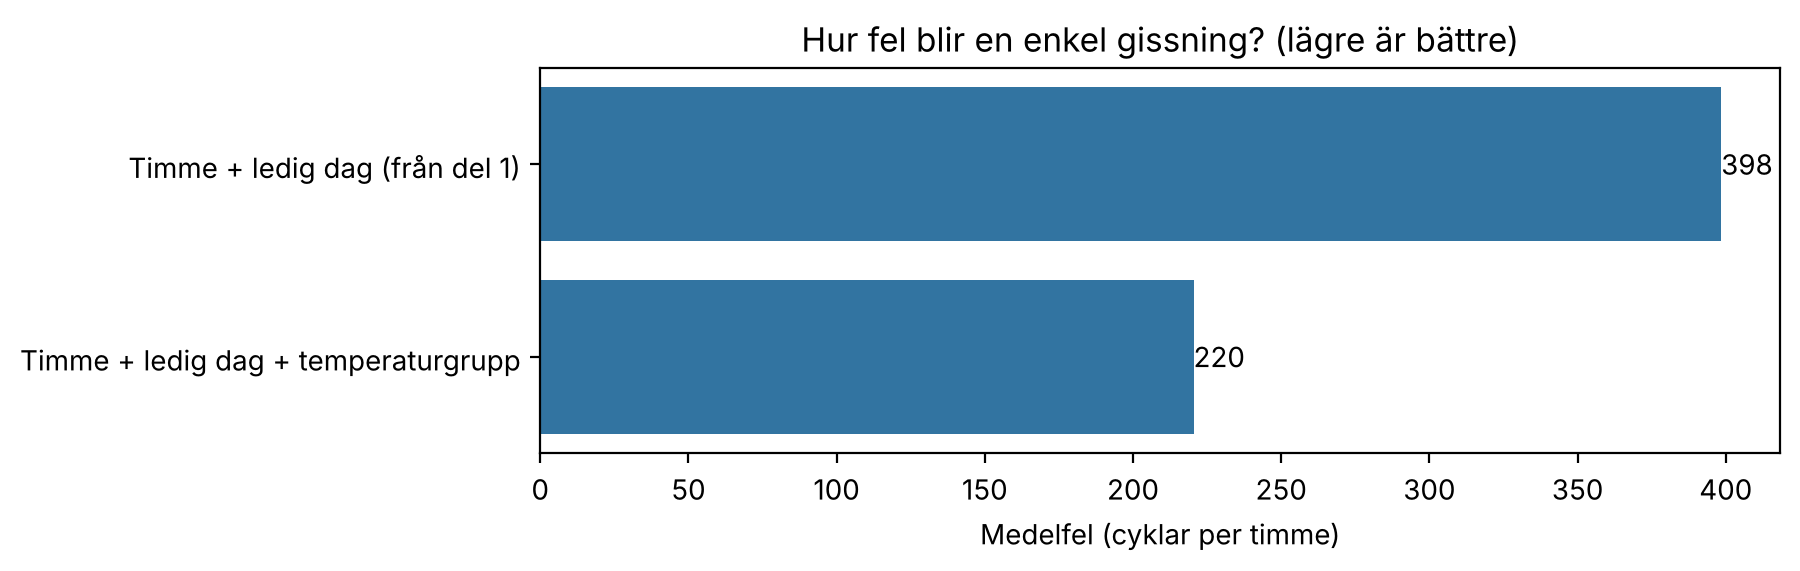

Rutor i tabellen: 192


In [ ]:
from sklearn.metrics import mean_absolute_error

gissning_ledig = df.groupby(["Hour", "Ledig dag"])[TARGET].transform("mean")
gissning_temp = df.groupby(["Hour", "Ledig dag", "Temperaturgrupp"], observed=True)[TARGET].transform("mean")

gissningar = pd.Series({
	"Timme + ledig dag (från del 1)": mean_absolute_error(df[TARGET], gissning_ledig),
	"Timme + ledig dag + temperaturgrupp": mean_absolute_error(df[TARGET], gissning_temp),
})

plt.figure(figsize=(8, 2.5))
ax = sns.barplot(x=gissningar.values, y=gissningar.index, color="tab:blue")
ax.bar_label(ax.containers[0], fmt="%.0f")
plt.title("Hur fel blir en enkel gissning? (lägre är bättre)")
plt.xlabel("Medelfel (cyklar per timme)")
plt.ylabel("")
plt.show()

print("Rutor i tabellen:", df.groupby(["Hour", "Ledig dag", "Temperaturgrupp"], observed=True).ngroups)

Bara fyra temperaturgrupper sänker felet från 398 till 220 cyklar per timme. Vädret
förklarar alltså en stor del av det som tiden inte förklarar.

Men tabellen har redan 192 rutor. Lägger vi till regn, luftfuktighet och sol blir rutorna
så många att vissa bara har någon enstaka timme. Då behövs en modell som hittar mönstren själv.

## Vad tar vi med oss till modellerna?
- **Temperaturen** är viktigast, men sambandet är en kurva.
- **Regn** är ovanligt men sänker uthyrningen till ungefär en femtedel.
- **Luftfuktighet** och **sol** tar vi med. **Daggpunkten** tar vi bort.
- **Snö** betyder lite när man redan vet temperaturen.
- **Vädret och timmen hänger ihop**, så modellen måste klara kombinationer och inte bara raka linjer.